# Chunking the EU AI Act (KAN-92, KAN-93)
Gözde Nur Özdemir · ELIZA · Sprint 2

**Goal:** split the AI Act into chunks, one chunk per provision in our provision list, and add metadata to each chunk.

**Why one chunk per provision?**
- The law is already split into numbered parts (Article, paragraph, point), and every answer must cite the exact part, for example Article 6(3)(a). If a chunk is one provision, the citation comes directly from the chunk.
- Fixed-size chunks (for example every 1,000 characters) cut provisions in the middle and mix two provisions in one chunk. Step 7 shows this with numbers.
- Splitting at the structure of the law worked better than fixed-size chunks on legal text (LegalBench-RAG; design decision D7).

**What we take:** the whole HTML is read, but only the 103 provisions in `data/provision-list.csv` become chunks. These are the provisions an EdTech developer needs for the high-risk question (scope C-01). The full text of each provision is kept; nothing is shortened or removed.

**How to run:** open this notebook from the `src/` folder of the repository. It reads `config/rag.yaml` and the files in `data/`, and writes `data/chunks.csv` and `data/chunks.jsonl`.

**Steps**
1. Load the HTML of the AI Act
2. Load the provision list.
3. Read the HTML into small units (paragraphs, points)
4. Build one chunk per provision
5. Split long chunks and link each chunk to the one before and after it
6. Save and look at the chunks
7. Compare with fixed-size chunks

## Summary
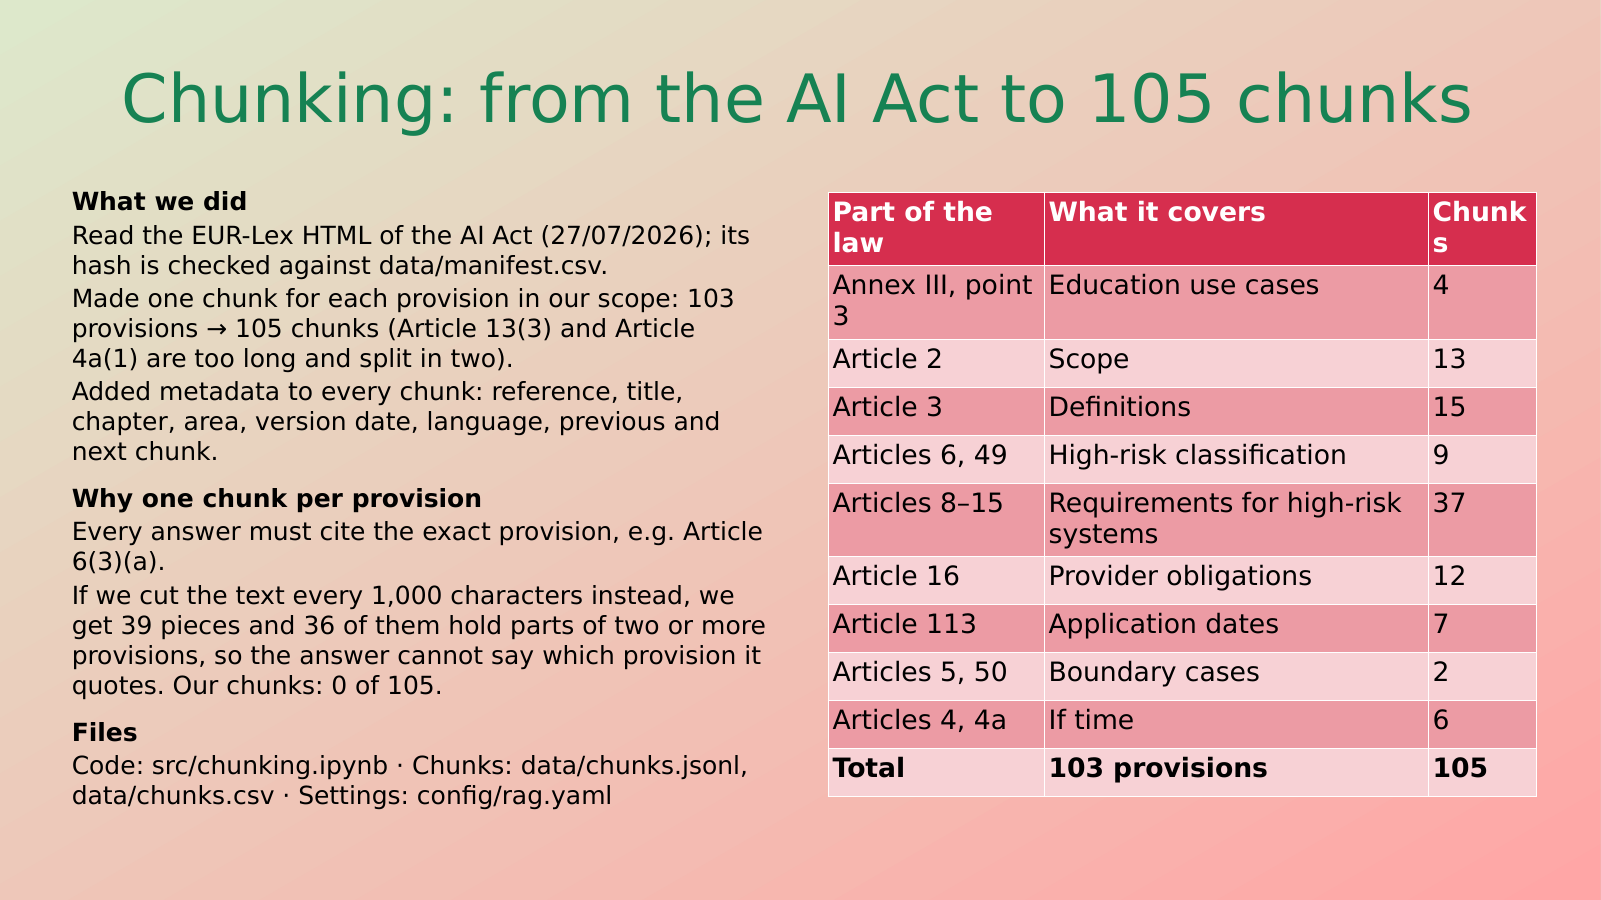

In [1]:
# Only in Google Colab: get the repository, so that the data and config files are there.
# On your own computer this cell does nothing.
import os, subprocess, sys
if "google.colab" in sys.modules:
    REPO = "/content/ELIZA_DI502_ORGANIZATION"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/ELIZA-DI502/ELIZA_DI502_ORGANIZATION.git", REPO], check=True)
    os.chdir(REPO + "/src")

In [2]:
# Install libraries
%pip -q install beautifulsoup4 pandas pyyaml

import csv, hashlib, io, json, os, re
import pandas as pd
import requests
import yaml
from bs4 import BeautifulSoup

CONFIG = yaml.safe_load(open("../config/rag.yaml"))["chunking"]   # the chunking settings
CONFIG

{'strategy': 'structure',
 'source_file': 'CELEX_02024R1689-20260727_EN.html',
 'version_date': '27/07/2026',
 'celex': '02024R1689-20260727',
 'max_chars': 1500}

## 1. Load the HTML
We use the consolidated text of 27/07/2026 from EUR-Lex (design decision D8).
The file is in `data/`. If it is missing, we download it from the link. Then we check its SHA-256 against `data/manifest.csv`, so that we always use the same version.

In [3]:
HTML_FILE = "../data/" + CONFIG["source_file"]
HTML_URL = "https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:" + CONFIG["celex"]

if not os.path.exists(HTML_FILE):
    r = requests.get(HTML_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
    r.raise_for_status()
    open(HTML_FILE, "wb").write(r.content)

# check that the file is the version written in data/manifest.csv (SRC-02)
manifest = {row["file"]: row["sha256"] for row in csv.DictReader(open("../data/manifest.csv", encoding="utf-8"))}
sha = hashlib.sha256(open(HTML_FILE, "rb").read()).hexdigest()
assert sha == manifest["data/" + CONFIG["source_file"]], "This HTML is not the version in data/manifest.csv"

html = open(HTML_FILE, encoding="utf-8").read()
soup = BeautifulSoup(html, "html.parser")
print("HTML size:", len(html), "characters")
print("SHA-256 matches data/manifest.csv:", sha)

HTML size: 850466 characters
SHA-256 matches data/manifest.csv: e7184c2b0a8037fb7e8ab8a98ab70832513579e841e520363bcca6a9ced0a2ea


**Comment:** The HTML file has about 850,000 characters. Its SHA-256 is the same as in `data/manifest.csv` (SRC-02), so we use exactly the version of the law we planned to use.

## 2. Load the provision list
`provision-list.csv` says which provisions are in our scope (C-01). Each row becomes one chunk.

In [4]:
LIST_FILE = "../data/provision-list.csv"
LIST_URL = "https://raw.githubusercontent.com/ELIZA-DI502/ELIZA_DI502_ORGANIZATION/main/data/provision-list.csv"

if not os.path.exists(LIST_FILE):
    open(LIST_FILE, "wb").write(requests.get(LIST_URL, timeout=60).content)

provisions = list(csv.DictReader(open(LIST_FILE, encoding="utf-8")))
print(len(provisions), "provisions, for example:", provisions[0]["reference"])
pd.DataFrame(provisions).groupby(["priority", "area"]).size().rename("provisions").reset_index()

103 provisions, for example: Annex III, point 3(a)


,priority,area,provisions
0,boundary,Boundary cases,2
1,core,Application dates,7
2,core,Education use cases,4
3,core,High-risk classification,9
4,core,Provider obligations,12
5,core,Requirements for high-risk systems,36
6,if-time,If time (not committed),5
7,supporting,Definitions,15
8,supporting,Scope,13


**Comment:** There are 103 provisions in our scope: 68 core, 28 supporting, 2 boundary and 5 if-time. Most core provisions are the requirements for high-risk systems (Articles 8 to 15).

## 3. Read the HTML into units
The HTML marks every part of the law:
- an Article is `<div id="art_6">`
- a numbered paragraph starts with `<span class="no-parag">3. </span>`
- a point like (a) is a list box (`grid-container`)

We walk through each Article and the Annexes and save every paragraph, subparagraph, point and sub-point as one **unit**.

In [5]:
units = []   # every small part of the law: paragraphs, subparagraphs, points

def text(el):
    """Returns the text of an HTML element with single spaces."""
    return re.sub(r"\s+", " ", el.get_text(" ")).strip()

def add(info, place, t):
    """Saves one unit: where it is in the law (info, place) and its text t."""
    units.append({**info, **place, "text": t})

def read_box(box, info, place, depth):
    """Reads a list box: '3.' (Annex area), '(a)' (point) or '(i)' (sub-point), then the boxes inside it.
    depth is 0 for the outer box, 1 for a box inside it, and so on."""
    label = text(box.find("div", class_="grid-list-column-1"))
    content = box.find("div", class_="grid-list-column-2")
    levels = ["point", "subpoint"] if info["kind"] == "article" else ["para", "point", "subpoint"]
    place = {**place, "sub": place["sub"] or 1}
    level = levels[min(depth, len(levels) - 1)]   # deeper boxes count as sub-points
    if level == "para":
        place.update(para=label.rstrip("."), point=None, subpoint=None)
    elif level == "point":
        place.update(point=label.strip("()"), subpoint=None)
    else:
        place["subpoint"] = label.strip("()")
    lines = [text(c) for c in content.find_all(recursive=False) if "grid-container" not in c.get("class", []) and text(c)]
    add(info, place, label + " " + "\n".join(lines))
    for small in content.find_all("div", class_="grid-container", recursive=False):
        read_box(small, info, place, depth + 1)

def walk(parent, info, place):
    """Goes through the children of an HTML element in order and saves every paragraph, subparagraph and point."""
    for el in parent.find_all(recursive=False):
        cls = el.get("class", [])
        number = el.find("span", class_="no-parag", recursive=False)
        if number:                                          # numbered paragraph "3."
            place.update(para=text(number).rstrip("."), sub=0, point=None, subpoint=None)
            start = len(units)
            walk(el, info, place)
            units[start]["text"] = place["para"] + ". " + units[start]["text"]
        elif el.name == "p" and "norm" in cls and text(el):  # a new subparagraph
            place.update(sub=place["sub"] + 1, point=None, subpoint=None)
            add(info, place, text(el))
        elif "inline-element" in cls and not el.find(["p", "div"], recursive=False):
            place["sub"] = 1                                # paragraph that is one block of text
            add(info, place, text(el))
        elif "inline-element" in cls:
            walk(el, info, place)
        elif "grid-container" in cls:                        # a point
            read_box(el, info, place, 0)

for div in soup.find_all("div", id=re.compile(r"^(art_\d+[a-z]?|anx_[IVX]+)$")):
    kind = "article" if div["id"].startswith("art") else "annex"
    title = div.find("p", class_=["stitle-article-norm", "title-annex-2"])
    chapter = div.find_parent(id=re.compile(r"^cpt_"))
    info = {"kind": kind, "num": div["id"].split("_")[1], "title": text(title) if title else "",
            "chapter": chapter["id"][4:].split(".")[0] if chapter and kind == "article" else ""}
    walk(div, info, {"para": None, "sub": 0, "point": None, "subpoint": None})

print(len(units), "units read from the HTML")

articles = {u["num"] for u in units if u["kind"] == "article"}
annexes = {u["num"] for u in units if u["kind"] == "annex"}
print(len(articles), "Articles and", len(annexes), "Annexes found")

# Article 6(3): a paragraph, a lead-in sentence, points (a) to (d) and a last subparagraph
cols = ["kind", "num", "para", "sub", "point", "subpoint", "text"]
pd.DataFrame(units)[cols].query("num == '6' and para == '3'").fillna("")   # empty = this unit has no point

1377 units read from the HTML
119 Articles and 12 Annexes found


,kind,num,para,sub,point,subpoint,text
171,article,6,3,1,,,"3. By derogation from paragraph 2, an AI syste..."
172,article,6,3,2,,,The first subparagraph shall apply where any o...
173,article,6,3,2,a,,(a) the AI system is intended to perform a nar...
174,article,6,3,2,b,,(b) the AI system is intended to improve the r...
175,article,6,3,2,c,,(c) the AI system is intended to detect decisi...
176,article,6,3,2,d,,(d) the AI system is intended to perform a pre...
177,article,6,3,3,,,"Notwithstanding the first subparagraph, an AI ..."


**Comment:** The HTML gave 1,377 small units. The table shows Article 6(3): the paragraph, the lead-in sentence, points (a) to (d) and the last subparagraph are separate units.

## 4. One chunk per provision
Each row of the provision list has a reference like `Article 6(3), second subparagraph, point (a)`.
We turn it into numbers (`num=6, para=3, sub=2, point=a`) and collect the units that match.

Each chunk gets:
- **text**: the provision itself (this is what an answer quotes)
- **embed_text**: heading + the sentence that introduces the point + text (this is what we search), so that a short point like "(a) …narrow procedural task" still makes sense
- **metadata**: reference, title, chapter, path, priority, version date, amendment

In [6]:
NUMBER = {"first": 1, "second": 2, "third": 3, "fourth": 4, "fifth": 5}

def parse_reference(ref):
    """'Article 6(3), second subparagraph, point (a)' -> num 6, para 3, sub 2, point a"""
    if ref.startswith("Annex"):                                    # Annex III, point 3(a)
        _, num, _, para, point = re.findall(r"\w+", ref)
        return {"kind": "annex", "num": num, "para": para, "sub": None, "point": point, "subpoint": None}
    num, para = re.match(r"Article (\w+)\(?(\w*)", ref).groups()   # Article 6(3)
    sub = re.search(r"(\w+) (?:sub)?paragraph", ref)               # second subparagraph
    points = re.findall(r"\((\w+)\)", ref.partition("point")[2]) + [None, None]   # point (c)(i)
    return {"kind": "article", "num": num, "para": para or None, "sub": NUMBER[sub[1]] if sub else None,
            "point": points[0], "subpoint": points[1]}

chunks = []
for row in provisions:
    ref = parse_reference(row["reference"])
    parts = [u for u in units if all(ref[k] in (None, u[k]) for k in ref)]   # the units of this provision
    if not parts:
        print("NOT FOUND:", row["reference"])
        continue
    u = parts[0]
    text = "\n".join(p["text"] for p in parts)
    # heading, e.g. "Article 6 – Classification rules for high-risk AI systems – paragraph 3:"
    name = ("Article " if u["kind"] == "article" else "Annex ") + u["num"]
    level = " – paragraph " if u["kind"] == "article" else " – point "
    heading = name + " – " + u["title"] + (level + ref["para"] if ref["para"] else "") + ":"
    # lead-in for a point, e.g. "The first subparagraph shall apply where ...:"
    lead = {**u, "point": u["point"] if ref["subpoint"] else None, "subpoint": None}
    intro = next((x["text"] for x in units if ref["point"] and x["text"].endswith(":")
                  and all(x[k] == lead[k] for k in ref)), "")
    chunks.append({
        "chunk_id": row["provision_id"], "ref": row["reference"],
        "parent": row["reference"].split(",")[0] if u["kind"] == "article" else row["reference"].split("(")[0],
        "kind": u["kind"], "number": u["num"], "title": u["title"], "chapter": u["chapter"],
        "priority": row["priority"], "area": row["area"], "amended_by": row["amended_by_2026_1744"],
        "version_date": CONFIG["version_date"], "celex": CONFIG["celex"], "language": "en",
        "source": "data/" + CONFIG["source_file"],
        "text": text, "heading": heading, "intro": intro,
        "embed_text": "\n".join(x for x in (heading, intro, text) if x),
        "order": units.index(u), "units": len(parts),
    })

chunks.sort(key=lambda c: c["order"])          # put them in the order of the law
print(len(chunks), "of", len(provisions), "provisions found")
print(sum(c["units"] for c in chunks), "of", len(units), "units are in our scope; the rest of the law is not used (C-01)")

103 of 103 provisions found
174 of 1377 units are in our scope; the rest of the law is not used (C-01)


**Comment:** All 103 provisions were found in the HTML, so nothing is missing. They use 174 of the 1,377 units; the other units are parts of the law outside our scope.

## 5. Split long chunks, link neighbours
- A provision longer than **1,500 characters** (`max_chars` in `config/rag.yaml`) is split at its points. Each part keeps the heading.
- Each chunk gets `prev_id` and `next_id`: the chunk before and after it in the same Article, so the retriever can add neighbours later.

In [7]:
MAX_CHARS = CONFIG["max_chars"]   # 1500, from config/rag.yaml

def split_text(text, limit):
    """Splits a text at its lines into pieces of at most `limit` characters (a line is never cut)."""
    pieces, current = [], ""
    for line in text.split("\n"):
        if current and len(current) + len(line) > limit:
            pieces.append(current)
            current = line
        else:
            current = (current + "\n" + line) if current else line
    return pieces + [current]

final = []
for c in chunks:
    if len(c["text"]) <= MAX_CHARS:
        final.append(c)
        continue
    pieces = split_text(c["text"], MAX_CHARS)
    for n, piece in enumerate(pieces, 1):
        final.append({**c, "chunk_id": f"{c['chunk_id']}#{n}", "part": f"{n}/{len(pieces)}", "text": piece,
                      "embed_text": "\n".join(x for x in (c["heading"], c["intro"], piece) if x)})

for i, c in enumerate(final):
    same = lambda other: other["kind"] == c["kind"] and other["number"] == c["number"]
    c["prev_id"] = final[i - 1]["chunk_id"] if i > 0 and same(final[i - 1]) else ""
    c["next_id"] = final[i + 1]["chunk_id"] if i + 1 < len(final) and same(final[i + 1]) else ""
    c["words"] = len(c["text"].split())

print(len(final), "chunks; split:", sorted({c["chunk_id"].split("#")[0] for c in final if "#" in c["chunk_id"]}))

105 chunks; split: ['ART13-3', 'ART4A-1']


**Comment:** Only two provisions were longer than 1,500 characters: Article 13(3) and Article 4a(1). Each was split into two parts, so we have 105 chunks in total.

## 6. Save and look at the chunks

In [8]:
with open("../data/chunks.jsonl", "w", encoding="utf-8") as f:
    for c in final:
        f.write(json.dumps(c, ensure_ascii=False) + "\n")
df = pd.DataFrame(final)
df.drop(columns=["embed_text", "heading", "intro", "order"]).to_csv("../data/chunks.csv", index=False)

print("saved data/chunks.jsonl and data/chunks.csv")
df["start"] = df["text"].str[:60] + "..."   # how each chunk begins
# examples of every kind: a paragraph, points, a sub-point, an Annex point and a split provision
examples = ["ART6-2", "ART6-3-a", "ART6-3-b", "ART16-a", "ART113-3-c-i", "ANX3-3-b", "ART4A-1#1", "ART4A-1#2"]
df[df["chunk_id"].isin(examples)][["chunk_id", "ref", "start", "prev_id", "next_id", "words"]]

saved data/chunks.jsonl and data/chunks.csv


,chunk_id,ref,start,prev_id,next_id,words
31,ART4A-1#1,Article 4a(1),1. To the extent strictly necessary to ensure ...,,ART4A-1#2,205
32,ART4A-1#2,Article 4a(1),(e) the special categories of personal data ar...,ART4A-1#1,ART4A-2,81
35,ART6-2,Article 6(2),2. In addition to the high-risk AI systems ref...,,ART6-3-1,26
37,ART6-3-a,"Article 6(3), second subparagraph, point (a)",(a) the AI system is intended to perform a nar...,ART6-3-1,ART6-3-b,12
38,ART6-3-b,"Article 6(3), second subparagraph, point (b)",(b) the AI system is intended to improve the r...,ART6-3-a,ART6-3-c,16
80,ART16-a,"Article 16, point (a)",(a) ensure that their high-risk AI systems are...,,ART16-b,17
98,ART113-3-c-i,"Article 113, third paragraph, point (c)(i)",(i) 2 December 2027 as regards AI systems clas...,ART113-3-b,ART113-3-c-ii,19
102,ANX3-3-b,"Annex III, point 3(b)",(b) AI systems intended to be used to evaluate...,ANX3-3-a,ANX3-3-c,34


**Comment:** The table shows one chunk of every kind: a paragraph, points, a sub-point, an Annex point and the two parts of a split provision. Each chunk points to the chunk before and after it in the same Article.

### Chunk statistics
How many chunks each area has and how long they are (in words).

In [9]:
summary = df.groupby(["priority", "area"]).agg(chunks=("chunk_id", "count"), min_words=("words", "min"),
                                              median_words=("words", "median"), max_words=("words", "max"))
print("All chunks: min", df["words"].min(), "words, median", df["words"].median(), "words, max", df["words"].max(), "words")
summary

All chunks: min 7 words, median 42.0 words, max 224 words


chunks  min_words  \
priority   area                                                    
boundary   Boundary cases                           2         59   
core       Application dates                        7          7   
           Education use cases                      4         26   
           High-risk classification                 9         12   
           Provider obligations                    12          9   
           Requirements for high-risk systems      37         14   
if-time    If time (not committed)                  6         35   
supporting Definitions                             15         15   
           Scope                                   13         23   

                                               median_words  max_words  
priority   area                                                         
boundary   Boundary cases                              85.0        111  
core       Application dates                           19.0         35  
           Education use cases                         32.5         42  
           High-risk classification                    28.0         62  
           Provider obligations                        18.5         39  
           Requirements for high-risk systems          57.0        224  
if-time    If time (not committed)                     86.5        205  
supporting Definitions                                 35.0         77  
           Scope                                       58.0        148

**Comment:** Most chunks are short: the median is 42 words and the longest is 224 words. The requirements for high-risk systems (Articles 8 to 15) have the most chunks, 37.

In [10]:
# Look at one chunk. Change the ID to see another one: ANX3-3-b, ART113-3-c-i, ART4A-1#1
c = next(c for c in final if c["chunk_id"] == "ART6-3-a")
print("TEXT:\n" + c["text"] + "\n")
print("EMBED_TEXT:\n" + c["embed_text"] + "\n")
for k in ["ref", "parent", "prev_id", "next_id", "chapter", "priority", "version_date", "amended_by"]:
    print(f"{k}: {c[k]}")

TEXT:
(a) the AI system is intended to perform a narrow procedural task;

EMBED_TEXT:
Article 6 – Classification rules for high-risk AI systems – paragraph 3:
The first subparagraph shall apply where any of the following conditions is fulfilled:
(a) the AI system is intended to perform a narrow procedural task;

ref: Article 6(3), second subparagraph, point (a)
parent: Article 6(3)
prev_id: ART6-3-1
next_id: ART6-3-b
chapter: III
priority: core
version_date: 27/07/2026
amended_by: 


**Comment:** Point (a) alone is very short and does not say what it belongs to. The embed text adds the Article heading and the sentence before the point, so the search can understand it.

## 7. Compare with fixed-size chunks
To check our choice, we also cut the same text into fixed-size pieces of 1,000 characters, as a simple RAG system would, and count how many pieces mix two or more provisions or start in the middle of a sentence.

In [11]:
SIZE = 1000
full, owner = "", []                      # owner: which provision each character belongs to
for c in final:
    full += c["text"] + "\n"
    owner += [c["chunk_id"].split("#")[0]] * (len(c["text"]) + 1)

pieces = [(full[i:i + SIZE], set(owner[i:i + SIZE])) for i in range(0, len(full), SIZE)]
mixed = sum(len(ids) > 1 for _, ids in pieces)
mid_sentence = sum(not text[0].isupper() and not text.startswith("(") and not text[0].isdigit() for text, _ in pieces[1:])

pd.DataFrame([
    {"method": "one chunk per provision (ours)", "chunks": len(final), "mix 2+ provisions": 0, "start mid-sentence": 0},
    {"method": f"fixed size, {SIZE} characters", "chunks": len(pieces), "mix 2+ provisions": mixed, "start mid-sentence": mid_sentence},
])

,method,chunks,mix 2+ provisions,start mid-sentence
0,one chunk per provision (ours),105,0,0
1,"fixed size, 1000 characters",39,36,36


**Comment:** With fixed-size pieces, 36 of the 39 pieces mix two or more provisions and 36 start in the middle of a sentence. A citation from such a piece could not point to one provision, so we keep one chunk per provision.